In [ ]:
# Check environment
import sys
import subprocess

print("Python version:", sys.version)
subprocess.run(["nvidia-smi"])

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]


CompletedProcess(args=['nvidia-smi'], returncode=0)

In [ ]:
%pip install -q openmm

In [ ]:
# Import openmm
try:
    import openmm
    print("OpenMM version:", openmm.__version__)
except ImportError:
    print("OpenMM is not installed.")

OpenMM version: 8.6.1


In [ ]:
!nvidia-smi

Sun Nov  1 18:57:07 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8             11W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import openmm as mm
import sys

print("Python:", sys.executable)
print("OpenMM version:", mm.__version__)

print("\nPlugin directory:")
print(mm.Platform.getDefaultPluginsDirectory())

print("\nPlugin loading failures:")
print(mm.Platform.getPluginLoadFailures())

print("\nAvailable platforms:")
for i in range(mm.Platform.getNumPlatforms()):
    print(mm.Platform.getPlatform(i).getName())

Python: /usr/bin/python3
OpenMM version: 8.6.1

Plugin directory:
/usr/local/openmm/lib/plugins

Plugin loading failures:
()

Available platforms:
Reference
CPU
OpenCL


In [ ]:
%pip show openmm

Name: OpenMM
Version: 8.6.1
Summary: Python wrapper for OpenMM (a C++ MD package)
Home-page: https://openmm.org
Author: Peter Eastman
Author-email: 
License: Python Software Foundation License (BSD-like)
Location: /usr/local/lib/python3.13/dist-packages
Requires: numpy
Required-by: 


In [ ]:
import openmm as mm
from openmm import unit

try:
    system = mm.System()
    system.addParticle(39.9 * unit.amu)

    integrator = mm.VerletIntegrator(
        0.001 * unit.picoseconds
    )

    platform = mm.Platform.getPlatformByName("OpenCL")

    context = mm.Context(
        system,
        integrator,
        platform
    )

    print("OpenCL initialized successfully!")
    print("Platform:", context.getPlatform().getName())

    print("Device:",
          platform.getPropertyValue(context, "OpenCLDeviceName"))

except Exception as e:
    print("OpenCL initialization failed:")
    print(type(e).__name__, str(e))

OpenCL initialized successfully!
Platform: OpenCL
Device: Tesla T4


In [ ]:
import openmm as mm
from openmm import unit

system = mm.System()
system.addParticle(39.9 * unit.amu)

integrator = mm.VerletIntegrator(
    0.002 * unit.picoseconds
)

platform = mm.Platform.getPlatformByName("OpenCL")

context = mm.Context(
    system,
    integrator,
    platform,
    {"Precision": "mixed"}
)

context.setPositions([[0, 0, 0]] * unit.nanometer)

integrator.step(100)

print("100 simulation steps completed!")
print("Platform:", context.getPlatform().getName())
print("Device:", platform.getPropertyValue(context, "OpenCLDeviceName"))

del context
del integrator

100 simulation steps completed!
Platform: OpenCL
Device: Tesla T4


In [ ]:
# Download the TNNT3 structure
import requests
import os

url = "https://alphafold.ebi.ac.uk/files/AF-P45378-2-F1-model_v6.pdb"
filename = "TNNT3_WT.pdb"

response = requests.get(url, timeout=60)
response.raise_for_status()

with open(filename, "wb") as f:
    f.write(response.content)

print("Downloaded:", filename)
print("File size:", os.path.getsize(filename), "bytes")

Downloaded: TNNT3_WT.pdb
File size: 179657 bytes


In [ ]:
# Check the protein structure
from openmm import app

pdb = app.PDBFile("TNNT3_WT.pdb")

print("Number of atoms:", pdb.topology.getNumAtoms())
print("Number of residues:", pdb.topology.getNumResidues())

for residue in pdb.topology.residues():
    if residue.id == "63":
        print("Residue 63:", residue.name)

Number of atoms: 2149
Number of residues: 258
Residue 63: ARG


In [ ]:
%pip install -q openmmforcefields

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
from openmm import app
from openmm import unit

forcefield = app.ForceField(
    "amber19-all.xml",
    "amber19/opc.xml"
)

modeller = app.Modeller(pdb.topology, pdb.positions)

modeller.addHydrogens(forcefield, pH=7.0)

print("Protein prepared!")
print("Atoms:", modeller.topology.getNumAtoms())

Protein prepared!
Atoms: 4308


In [ ]:
# Create a solvated system
modeller.addSolvent(
    forcefield,
    model="tip4pew",
    padding=0.9 * unit.nanometer,
    ionicStrength=0.15 * unit.molar
)

print("Solvation complete!")
print("Total atoms:", modeller.topology.getNumAtoms())

Solvation complete!
Total atoms: 678875


In [ ]:
# Save the system
with open("TNNT3_WT_solvated.pdb", "w") as f:
    app.PDBFile.writeFile(
        modeller.topology,
        modeller.positions,
        f,
        keepIds=True
    )

print("Saved TNNT3_WT_solvated.pdb")

Saved TNNT3_WT_solvated.pdb


In [ ]:
# Build the simulation system
import openmm as mm
from openmm import app, unit

system = forcefield.createSystem(
    modeller.topology,
    nonbondedMethod=app.PME,
    nonbondedCutoff=0.8 * unit.nanometer,
    constraints=app.HBonds,
    rigidWater=True
)

integrator = mm.LangevinMiddleIntegrator(
    298 * unit.kelvin,
    1.0 / unit.picosecond,
    0.002 * unit.picoseconds
)

platform = mm.Platform.getPlatformByName("OpenCL")

simulation = app.Simulation(
    modeller.topology,
    system,
    integrator,
    platform,
    {"Precision": "mixed"}
)

simulation.context.setPositions(modeller.positions)

print("Simulation system created successfully!")
print("Platform:", simulation.context.getPlatform().getName())

Simulation system created successfully!
Platform: OpenCL


In [ ]:
# Energy minmization
import time

print("Starting energy minimization...")

start = time.time()

simulation.minimizeEnergy(
    tolerance=10 * unit.kilojoule_per_mole / unit.nanometer,
    maxIterations=1000
)

elapsed = time.time() - start

state = simulation.context.getState(
    getEnergy=True,
    getPositions=True
)

print("Energy minimization completed!")
print("Time:", round(elapsed, 2), "seconds")
print("Potential energy:", state.getPotentialEnergy())

Starting energy minimization...
Energy minimization completed!
Time: 74.42 seconds
Potential energy: -10546324.104750663 kJ/mol


In [ ]:
with open("TNNT3_WT_minimized.pdb", "w") as f:
    app.PDBFile.writeFile(
        modeller.topology,
        state.getPositions(),
        f,
        keepIds=True
    )

with open("TNNT3_WT_system.xml", "w") as f:
    f.write(mm.XmlSerializer.serialize(system))

simulation.saveCheckpoint("TNNT3_WT_minimized.chk")

print("Files saved successfully!")

Files saved successfully!


In [ ]:
# Equilibrate TNNT3
from openmm import unit
import openmm as mm

restraint = mm.CustomExternalForce(
    "0.5*k*((x-x0)^2+(y-y0)^2+(z-z0)^2)"
)

restraint.addGlobalParameter(
    "k", 500.0 * unit.kilojoule_per_mole / unit.nanometer**2
)

for name in ["x0", "y0", "z0"]:
    restraint.addPerParticleParameter(name)

state = simulation.context.getState(getPositions=True)
positions = state.getPositions(asNumpy=True)

count = 0

for atom in modeller.topology.atoms():
    if atom.name in ["N", "CA", "C", "O"] and atom.residue.name not in ["HOH"]:
        pos = positions[atom.index].value_in_unit(unit.nanometer)
        restraint.addParticle(atom.index, pos)
        count += 1

system.addForce(restraint)

print("Restrained backbone atoms:", count)

Restrained backbone atoms: 1032


In [ ]:
simulation.context.reinitialize(preserveState=True)

simulation.context.setVelocitiesToTemperature(
    298 * unit.kelvin
)

print("System ready for restrained equilibration.")

System ready for restrained equilibration.


In [ ]:
import sys
import time

simulation.reporters.append(
    app.StateDataReporter(
        sys.stdout,
        500,
        step=True,
        potentialEnergy=True,
        temperature=True,
        speed=True
    )
)

In [ ]:
import numpy as np
from openmm import app, unit

pdb = app.PDBFile("TNNT3_WT_minimized.pdb")

positions = pdb.positions.value_in_unit(unit.nanometer)

print("Number of atoms:", len(positions))
print("All coordinates finite:", np.isfinite(positions).all())
print("Maximum coordinate magnitude:", np.abs(positions).max())

Number of atoms: 678875
All coordinates finite: True
Maximum coordinate magnitude: 10.0806


In [ ]:
import openmm as mm
from openmm import app, unit

# Recreate system without the previous restraint
system = forcefield.createSystem(
    modeller.topology,
    nonbondedMethod=app.PME,
    nonbondedCutoff=0.8 * unit.nanometer,
    constraints=app.HBonds,
    rigidWater=True
)

# Start with a smaller timestep
integrator = mm.LangevinMiddleIntegrator(
    298 * unit.kelvin,
    5.0 / unit.picosecond,
    0.001 * unit.picoseconds
)

platform = mm.Platform.getPlatformByName("OpenCL")

simulation = app.Simulation(
    modeller.topology,
    system,
    integrator,
    platform,
    {"Precision": "mixed"}
)

simulation.context.setPositions(pdb.positions)

print("Fresh simulation created.")

Fresh simulation created.


In [ ]:
simulation.minimizeEnergy(
    tolerance=10 * unit.kilojoule_per_mole / unit.nanometer,
    maxIterations=2000
)

simulation.context.setVelocitiesToTemperature(
    298 * unit.kelvin
)

print("Starting 100-step test...")

try:
    simulation.step(100)

    state = simulation.context.getState(
        getEnergy=True,
        getPositions=True
    )

    coords = state.getPositions(
        asNumpy=True
    ).value_in_unit(unit.nanometer)

    print("100 steps completed!")
    print("Coordinates finite:", np.isfinite(coords).all())
    print("Potential energy:", state.getPotentialEnergy())

except Exception as e:
    print("Simulation failed:", str(e))

Starting 100-step test...
100 steps completed!
Coordinates finite: True
Potential energy: -9661039.72005193 kJ/mol


In [ ]:
import numpy as np
from openmm import unit

coords = np.array([
    pos.value_in_unit(unit.nanometer)
    for atom, pos in zip(modeller.topology.atoms(), modeller.positions)
    if atom.residue.name not in ["HOH", "NA", "CL"]
])

dimensions = coords.max(axis=0) - coords.min(axis=0)

print("Protein dimensions (nm):", dimensions)
print("Protein dimensions (Å):", dimensions * 10)

print("Total atoms:", modeller.topology.getNumAtoms())

Protein dimensions (nm): [10.58393621  9.4774127  10.82714605]
Protein dimensions (Å): [105.83936214  94.77412701 108.27146053]
Total atoms: 678875


In [ ]:
from collections import Counter

residues = Counter(
    residue.name
    for residue in modeller.topology.residues()
)

print("Water molecules:", residues.get("HOH", 0))
print("Sodium ions:", residues.get("NA", 0))
print("Chloride ions:", residues.get("CL", 0))

Water molecules: 168412
Sodium ions: 461
Chloride ions: 458


In [ ]:
from openmm import app, unit

# Reload original unsolvated TNNT3 structure
pdb = app.PDBFile("TNNT3_WT.pdb")

# Recreate the protein-only model
small_modeller = app.Modeller(
    pdb.topology,
    pdb.positions
)

# Add hydrogens
small_modeller.addHydrogens(
    forcefield,
    pH=7.0
)

print("Protein atoms:",
      small_modeller.topology.getNumAtoms())

Protein atoms: 4308


In [ ]:
small_modeller.addSolvent(
    forcefield,
    model="tip4pew",
    padding=0.8 * unit.nanometer,
    ionicStrength=0.15 * unit.molar,
    boxShape="dodecahedron"
)

print("New total atoms:",
      small_modeller.topology.getNumAtoms())

print("New water molecules:",
      sum(
          1 for r in small_modeller.topology.residues()
          if r.name == "HOH"
      ))

New total atoms: 470413
New water molecules: 116367


In [ ]:
import numpy as np
from openmm import unit

vectors = small_modeller.topology.getPeriodicBoxVectors()

box = np.array([
    v.value_in_unit(unit.nanometer)
    for v in vectors
])

print("Periodic box vectors (nm):")
print(box)

print("\nVector lengths (nm):")
print(np.linalg.norm(box, axis=1))

print("\nBox volume (nm³):")
print(abs(np.linalg.det(box)))

Periodic box vectors (nm):
[[17.25603238  0.          0.        ]
 [ 0.         17.25603238  0.        ]
 [ 8.62801619  8.62801619 12.20185751]]

Vector lengths (nm):
[17.25603238 17.25603238 17.25603238]

Box volume (nm³):
3633.3550826824417


In [ ]:
%pip install -q biopython

from Bio.PDB import PDBParser

parser = PDBParser(QUIET=True)
structure = parser.get_structure("TNNT3", "TNNT3_WT.pdb")

for residue in structure.get_residues():
    if residue.id[1] == 63:
        print("Residue:", residue.resname)
        print("Residue 63 confidence:",
              residue["CA"].bfactor)

Residue: ARG
Residue 63 confidence: 90.94


In [ ]:
from openmm import app

with open("TNNT3_WT_small_solvated.pdb", "w") as f:
    app.PDBFile.writeFile(
        small_modeller.topology,
        small_modeller.positions,
        f,
        keepIds=True
    )

print("Smaller TNNT3 system saved.")

Smaller TNNT3 system saved.


In [ ]:
import openmm as mm
from openmm import app, unit
import time
import numpy as np

small_system = forcefield.createSystem(
    small_modeller.topology,
    nonbondedMethod=app.PME,
    nonbondedCutoff=0.8 * unit.nanometer,
    constraints=app.HBonds,
    rigidWater=True
)

small_integrator = mm.LangevinMiddleIntegrator(
    298 * unit.kelvin,
    5.0 / unit.picosecond,
    0.001 * unit.picoseconds
)

platform = mm.Platform.getPlatformByName("OpenCL")

small_simulation = app.Simulation(
    small_modeller.topology,
    small_system,
    small_integrator,
    platform,
    {"Precision": "mixed"}
)

small_simulation.context.setPositions(
    small_modeller.positions
)

print("System created successfully!")
print("Atoms:", small_modeller.topology.getNumAtoms())

System created successfully!
Atoms: 470413


In [ ]:
print("Starting minimization...")

start = time.time()

small_simulation.minimizeEnergy(
    tolerance=10 * unit.kilojoule_per_mole / unit.nanometer,
    maxIterations=1000
)

elapsed = time.time() - start

state = small_simulation.context.getState(
    getEnergy=True,
    getPositions=True
)

coords = state.getPositions(
    asNumpy=True
).value_in_unit(unit.nanometer)

print("Minimization completed!")
print("Time:", round(elapsed, 2), "seconds")
print("Potential energy:", state.getPotentialEnergy())
print("Coordinates finite:", np.isfinite(coords).all())

Starting minimization...
Minimization completed!
Time: 75.18 seconds
Potential energy: -7306611.487538159 kJ/mol
Coordinates finite: True


In [ ]:
with open("TNNT3_WT_small_minimized.pdb", "w") as f:
    app.PDBFile.writeFile(
        small_modeller.topology,
        state.getPositions(),
        f,
        keepIds=True
    )

with open("TNNT3_WT_small_system.xml", "w") as f:
    f.write(mm.XmlSerializer.serialize(small_system))

small_simulation.saveCheckpoint(
    "TNNT3_WT_small_minimized.chk"
)

print("Minimized system saved.")

Minimized system saved.


In [ ]:
from openmm import unit
import openmm as mm
import numpy as np

# Get minimized positions
state = small_simulation.context.getState(getPositions=True)
positions = state.getPositions(asNumpy=True)

# Create harmonic positional restraints
restraint = mm.CustomExternalForce(
    "0.5*k*((x-x0)^2+(y-y0)^2+(z-z0)^2)"
)

restraint.addGlobalParameter(
    "k", 500.0 * unit.kilojoule_per_mole / unit.nanometer**2
)

for parameter in ["x0", "y0", "z0"]:
    restraint.addPerParticleParameter(parameter)

count = 0

for atom in small_modeller.topology.atoms():
    if atom.name in ["N", "CA", "C", "O"] and atom.residue.name not in ["HOH"]:
        pos = positions[atom.index].value_in_unit(unit.nanometer)
        restraint.addParticle(atom.index, pos)
        count += 1

small_system.addForce(restraint)

print("Backbone atoms restrained:", count)

Backbone atoms restrained: 1032


In [ ]:
small_simulation.context.reinitialize(preserveState=True)

small_simulation.context.setVelocitiesToTemperature(
    298 * unit.kelvin
)

print("Ready for equilibration.")

Ready for equilibration.


In [ ]:
import openmm as mm
from openmm import app, unit
import numpy as np

pdb = app.PDBFile("TNNT3_WT_small_minimized.pdb")

# Rebuild without positional restraints
test_system = forcefield.createSystem(
    pdb.topology,
    nonbondedMethod=app.PME,
    nonbondedCutoff=0.8 * unit.nanometer,
    constraints=app.HBonds,
    rigidWater=True
)

test_integrator = mm.LangevinMiddleIntegrator(
    298 * unit.kelvin,
    5.0 / unit.picosecond,
    0.0005 * unit.picoseconds
)

test_sim = app.Simulation(
    pdb.topology,
    test_system,
    test_integrator,
    mm.Platform.getPlatformByName("OpenCL"),
    {"Precision": "mixed"}
)

test_sim.context.setPositions(pdb.positions)

state = test_sim.context.getState(
    getEnergy=True,
    getForces=True
)

forces = state.getForces(
    asNumpy=True
).value_in_unit(unit.kilojoule_per_mole / unit.nanometer)

print("Potential energy:", state.getPotentialEnergy())
print("All forces finite:", np.isfinite(forces).all())
print("Maximum force:", np.linalg.norm(forces, axis=1).max())

Potential energy: -7306512.017424151 kJ/mol
All forces finite: True
Maximum force: 3918.6104351107024


In [ ]:
test_sim.context.setVelocitiesToTemperature(
    298 * unit.kelvin
)

try:
    for i in range(10):
        test_sim.step(10)

        state = test_sim.context.getState(
            getPositions=True,
            getEnergy=True
        )

        coords = state.getPositions(
            asNumpy=True
        ).value_in_unit(unit.nanometer)

        energy = state.getPotentialEnergy().value_in_unit(
            unit.kilojoule_per_mole
        )

        print(
            f"Step {(i+1)*10}:",
            f"Energy = {energy:.2f}",
            f"Finite = {np.isfinite(coords).all()}"
        )

except Exception as e:
    print("Failed:", str(e))

Step 10: Energy = -7104635.76 Finite = True
Step 20: Energy = -6869416.17 Finite = True
Step 30: Energy = -6874816.42 Finite = True
Step 40: Energy = -6920507.60 Finite = True
Step 50: Energy = -6880359.46 Finite = True
Step 60: Energy = -6843482.84 Finite = True
Step 70: Energy = -6817376.26 Finite = True
Step 80: Energy = -6795446.70 Finite = True
Step 90: Energy = -6806461.47 Finite = True
Step 100: Energy = -6815493.10 Finite = True


In [ ]:
import numpy as np
import time
from openmm import unit

print("Starting extended stability test...")

start = time.time()

try:
    for i in range(20):
        test_sim.step(100)

        state = test_sim.context.getState(
            getPositions=True,
            getEnergy=True
        )

        coords = state.getPositions(
            asNumpy=True
        ).value_in_unit(unit.nanometer)

        energy = state.getPotentialEnergy().value_in_unit(
            unit.kilojoule_per_mole
        )

        finite = np.isfinite(coords).all()

        print(
            f"Step {(i+1)*100 + 100}: "
            f"Energy = {energy:.2f}, "
            f"Finite = {finite}"
        )

        if not finite or not np.isfinite(energy):
            print("Nonfinite values detected. Stopping.")
            break

except Exception as e:
    print("Simulation failed:", str(e))

print("Elapsed time:", round(time.time() - start, 2), "seconds")

Starting extended stability test...
Step 200: Energy = -6690647.08, Finite = True
Step 300: Energy = -6613502.29, Finite = True
Step 400: Energy = -6558926.74, Finite = True
Step 500: Energy = -6515073.14, Finite = True
Step 600: Energy = -6476655.38, Finite = True
Step 700: Energy = -6445628.29, Finite = True
Step 800: Energy = -6420592.48, Finite = True
Step 900: Energy = -6397992.80, Finite = True
Step 1000: Energy = -6384258.06, Finite = True
Step 1100: Energy = -6368851.91, Finite = True
Step 1200: Energy = -6358010.60, Finite = True
Step 1300: Energy = -6346278.61, Finite = True
Step 1400: Energy = -6337934.40, Finite = True
Step 1500: Energy = -6328583.65, Finite = True
Step 1600: Energy = -6321374.97, Finite = True
Step 1700: Energy = -6315304.29, Finite = True
Step 1800: Energy = -6313496.05, Finite = True
Step 1900: Energy = -6307636.70, Finite = True
Step 2000: Energy = -6305620.81, Finite = True
Step 2100: Energy = -6301896.08, Finite = True
Elapsed time: 47.14 seconds


In [ ]:
from openmm import unit
import numpy as np

state = test_sim.context.getState(
    getEnergy=True,
    getVelocities=True
)

kinetic = state.getKineticEnergy()
potential = state.getPotentialEnergy()

# OpenMM's temperature calculation accounts for constrained degrees of freedom
dof = 0
for i in range(test_system.getNumParticles()):
    if test_system.getParticleMass(i) > 0 * unit.dalton:
        dof += 3

dof -= test_system.getNumConstraints()

for force in test_system.getForces():
    if isinstance(force, mm.CMMotionRemover):
        dof -= 3

temperature = (
    2 * kinetic /
    (dof * unit.MOLAR_GAS_CONSTANT_R)
).value_in_unit(unit.kelvin)

print(f"Temperature: {temperature:.2f} K")
print("Kinetic energy:", kinetic)
print("Potential energy:", potential)
print("Degrees of freedom:", dof)

Temperature: 295.05 K
Kinetic energy: 871958.9080686782 kJ/mol
Potential energy: -6301896.075261712 kJ/mol
Degrees of freedom: 710875


In [ ]:
test_sim.saveState("TNNT3_WT_1ps_stable.xml")
test_sim.saveCheckpoint("TNNT3_WT_1ps_stable.chk")

print("Simulation saved successfully.")

Simulation saved successfully.


In [ ]:
import numpy as np
import time
from openmm import unit

print("Starting 5 ps NVT extension...")

start = time.time()

try:
    for i in range(10):
        test_sim.step(1000)

        state = test_sim.context.getState(
            getEnergy=True,
            getPositions=True
        )

        energy = state.getPotentialEnergy().value_in_unit(
            unit.kilojoule_per_mole
        )

        coords = state.getPositions(
            asNumpy=True
        ).value_in_unit(unit.nanometer)

        print(
            f"Additional steps: {(i+1)*1000}, "
            f"Energy: {energy:.2f} kJ/mol, "
            f"Finite: {np.isfinite(coords).all()}"
        )

        if not np.isfinite(energy) or not np.isfinite(coords).all():
            print("Nonfinite values detected. Stopping.")
            break

except Exception as e:
    print("Simulation failed:", str(e))

print("Elapsed time:", round(time.time() - start, 2), "seconds")

Starting 5 ps NVT extension...
Additional steps: 1000, Energy: -6285917.60 kJ/mol, Finite: True
Additional steps: 2000, Energy: -6279017.17 kJ/mol, Finite: True
Additional steps: 3000, Energy: -6282961.92 kJ/mol, Finite: True
Additional steps: 4000, Energy: -6275006.71 kJ/mol, Finite: True
Additional steps: 5000, Energy: -6272558.33 kJ/mol, Finite: True
Additional steps: 6000, Energy: -6275336.20 kJ/mol, Finite: True
Additional steps: 7000, Energy: -6276162.35 kJ/mol, Finite: True
Additional steps: 8000, Energy: -6275245.18 kJ/mol, Finite: True
Additional steps: 9000, Energy: -6274839.62 kJ/mol, Finite: True
Additional steps: 10000, Energy: -6270503.01 kJ/mol, Finite: True
Elapsed time: 225.29 seconds


In [ ]:
state = test_sim.context.getState(getEnergy=True)

temperature = (
    2 * state.getKineticEnergy() /
    (dof * unit.MOLAR_GAS_CONSTANT_R)
).value_in_unit(unit.kelvin)

print(f"Final temperature: {temperature:.2f} K")
print("Final potential energy:", state.getPotentialEnergy())

Final temperature: 297.37 K
Final potential energy: -6270503.005023524 kJ/mol


In [ ]:
test_sim.saveState("TNNT3_WT_6ps.xml")
test_sim.saveCheckpoint("TNNT3_WT_6ps.chk")

print("6 ps simulation saved successfully.")

6 ps simulation saved successfully.


In [ ]:
import numpy as np
from openmm import unit

# Current coordinates
state = test_sim.context.getState(getPositions=True)

current = state.getPositions(
    asNumpy=True
).value_in_unit(unit.nanometer)

# Reference coordinates from minimized PDB
reference = pdb.positions.value_in_unit(unit.nanometer)

# Select protein backbone atoms
indices = [
    atom.index
    for atom in pdb.topology.atoms()
    if atom.name in ["N", "CA", "C", "O"]
    and atom.residue.name not in ["HOH"]
]

P = np.asarray(reference)[indices]
Q = np.asarray(current)[indices]

# Center both structures
P = P - P.mean(axis=0)
Q = Q - Q.mean(axis=0)

# Kabsch alignment
H = Q.T @ P
U, S, Vt = np.linalg.svd(H)

D = np.eye(3)
D[-1, -1] = np.linalg.det(U @ Vt)

rotation = U @ D @ Vt

Q_aligned = Q @ rotation

rmsd = np.sqrt(
    np.mean(
        np.sum((P - Q_aligned)**2, axis=1)
    )
)

print(f"Backbone RMSD: {rmsd:.4f} nm")
print(f"Backbone RMSD: {rmsd * 10:.3f} Å")

Backbone RMSD: 0.1138 nm
Backbone RMSD: 1.138 Å


In [ ]:
import numpy as np
import pandas as pd
import time
from openmm import unit

records = []

def backbone_rmsd_nm(reference, current, indices):
    P = np.asarray(reference)[indices].copy()
    Q = np.asarray(current)[indices].copy()

    P -= P.mean(axis=0)
    Q -= Q.mean(axis=0)

    H = Q.T @ P
    U, _, Vt = np.linalg.svd(H)

    D = np.eye(3)
    D[-1, -1] = np.linalg.det(U @ Vt)

    Q_aligned = Q @ (U @ D @ Vt)

    return np.sqrt(np.mean(np.sum((P - Q_aligned)**2, axis=1)))

print("Starting 10 ps monitoring run...")

for i in range(20):
    test_sim.step(1000)

    state = test_sim.context.getState(
        getPositions=True,
        getEnergy=True
    )

    coords = state.getPositions(
        asNumpy=True
    ).value_in_unit(unit.nanometer)

    if not np.isfinite(coords).all():
        raise RuntimeError("Nonfinite coordinates detected")

    temperature = (
        2 * state.getKineticEnergy() /
        (dof * unit.MOLAR_GAS_CONSTANT_R)
    ).value_in_unit(unit.kelvin)

    potential = state.getPotentialEnergy().value_in_unit(
        unit.kilojoule_per_mole
    )

    rmsd = backbone_rmsd_nm(reference, coords, indices)

    records.append({
        "Additional time (ps)": (i + 1) * 0.5,
        "Temperature (K)": temperature,
        "Potential energy (kJ/mol)": potential,
        "Backbone RMSD (nm)": rmsd
    })

    print(
        f"{(i+1)*0.5:.1f} ps | "
        f"T={temperature:.2f} K | "
        f"RMSD={rmsd:.4f} nm"
    )

results = pd.DataFrame(records)
results.to_csv("TNNT3_WT_monitoring.csv", index=False)

print("Monitoring completed.")

Starting 10 ps monitoring run...
0.5 ps | T=298.08 K | RMSD=0.1156 nm
1.0 ps | T=298.62 K | RMSD=0.1214 nm
1.5 ps | T=297.89 K | RMSD=0.1244 nm
2.0 ps | T=297.71 K | RMSD=0.1262 nm
2.5 ps | T=298.81 K | RMSD=0.1276 nm
3.0 ps | T=298.37 K | RMSD=0.1302 nm
3.5 ps | T=298.66 K | RMSD=0.1343 nm
4.0 ps | T=298.29 K | RMSD=0.1376 nm
4.5 ps | T=298.65 K | RMSD=0.1408 nm
5.0 ps | T=297.29 K | RMSD=0.1429 nm
5.5 ps | T=298.31 K | RMSD=0.1447 nm
6.0 ps | T=298.05 K | RMSD=0.1491 nm
6.5 ps | T=297.78 K | RMSD=0.1469 nm
7.0 ps | T=299.38 K | RMSD=0.1471 nm
7.5 ps | T=297.88 K | RMSD=0.1510 nm
8.0 ps | T=297.49 K | RMSD=0.1537 nm
8.5 ps | T=298.05 K | RMSD=0.1572 nm
9.0 ps | T=298.58 K | RMSD=0.1601 nm
9.5 ps | T=298.43 K | RMSD=0.1608 nm
10.0 ps | T=298.19 K | RMSD=0.1590 nm
Monitoring completed.


In [ ]:
test_sim.saveState("TNNT3_WT_16ps.xml")
test_sim.saveCheckpoint("TNNT3_WT_16ps.chk")

In [ ]:
from google.colab import drive
import os
import shutil

drive.mount("/content/drive")

folder = "/content/drive/MyDrive/TNNT3_MD"
os.makedirs(folder, exist_ok=True)

test_sim.saveState("TNNT3_WT_16ps.xml")
test_sim.saveCheckpoint("TNNT3_WT_16ps.chk")

for filename in [
    "TNNT3_WT_16ps.xml",
    "TNNT3_WT_16ps.chk",
    "TNNT3_WT_monitoring.csv",
    "TNNT3_WT_small_minimized.pdb"
]:
    if os.path.exists(filename):
        shutil.copy2(filename, folder)
        print("Saved:", filename)

Mounted at /content/drive
Saved: TNNT3_WT_16ps.xml
Saved: TNNT3_WT_16ps.chk
Saved: TNNT3_WT_monitoring.csv
Saved: TNNT3_WT_small_minimized.pdb


In [ ]:
import pandas as pd

results = pd.read_csv("TNNT3_WT_monitoring.csv")

print("Temperature summary:")
print(results["Temperature (K)"].describe())

print("\nRMSD summary:")
print(results["Backbone RMSD (nm)"].describe())

print("\nFinal 5 ps mean RMSD:")
print(
    results.loc[
        results["Additional time (ps)"] > 5,
        "Backbone RMSD (nm)"
    ].mean()
)

Temperature summary:
count     20.000000
mean     298.224969
std        0.491336
min      297.287189
25%      297.888459
50%      298.240298
75%      298.586327
max      299.378697
Name: Temperature (K), dtype: float64

RMSD summary:
count    20.000000
mean      0.141533
std       0.013833
min       0.115617
25%       0.129565
50%       0.143804
75%       0.151680
max       0.160797
Name: Backbone RMSD (nm), dtype: float64

Final 5 ps mean RMSD:
0.15297094831866526


In [ ]:
import numpy as np
from openmm import unit

vectors = test_sim.context.getState().getPeriodicBoxVectors()

box = np.array([
    v.value_in_unit(unit.nanometer)
    for v in vectors
])

volume = abs(np.linalg.det(box))

print("Periodic box vectors (nm):")
print(box)
print("Box volume (nm³):", volume)
print("Shortest box vector (nm):",
      np.linalg.norm(box, axis=1).min())

Periodic box vectors (nm):
[[17.256       0.          0.        ]
 [ 0.         17.256       0.        ]
 [-8.628      -8.628      12.20183462]]
Box volume (nm³): 3633.334632001234
Shortest box vector (nm): 17.255999999999997


In [ ]:
import numpy as np
from scipy.spatial import cKDTree
from itertools import product
from openmm import unit

state = test_sim.context.getState(getPositions=True)

coords = state.getPositions(
    asNumpy=True
).value_in_unit(unit.nanometer)

vectors = state.getPeriodicBoxVectors()

box = np.array([
    v.value_in_unit(unit.nanometer)
    for v in vectors
])

protein_indices = [
    atom.index
    for atom in pdb.topology.atoms()
    if atom.residue.name not in ["HOH", "NA", "CL"]
    and atom.element is not None
    and atom.element.symbol != "H"
]

protein = coords[protein_indices]

tree = cKDTree(protein)

minimum_distance = np.inf
closest_image = None

for shift in product([-1, 0, 1], repeat=3):
    if shift == (0, 0, 0):
        continue

    translation = np.array(shift) @ box
    shifted = protein + translation

    distances, _ = tree.query(shifted, k=1)

    distance = distances.min()

    if distance < minimum_distance:
        minimum_distance = distance
        closest_image = shift

print(f"Minimum protein-image distance: {minimum_distance:.3f} nm")
print("Closest periodic image:", closest_image)

Minimum protein-image distance: 3.479 nm
Closest periodic image: (0, 0, -1)


In [ ]:
from openmm import app

# Save trajectory frames every 1000 steps (0.5 ps)
test_sim.reporters.append(
    app.DCDReporter("TNNT3_WT_equilibration.dcd", 1000)
)

# Save thermodynamic measurements
test_sim.reporters.append(
    app.StateDataReporter(
        "TNNT3_WT_equilibration.csv",
        1000,
        step=True,
        time=True,
        potentialEnergy=True,
        kineticEnergy=True,
        temperature=True,
        speed=True,
        separator=","
    )
)

print("Trajectory and monitoring reporters configured.")

Trajectory and monitoring reporters configured.


In [ ]:
import time
import numpy as np
from openmm import unit

print("Starting extended TNNT3 equilibration...")

start = time.time()
completed = 0

try:
    for i in range(17):
        test_sim.step(4000)
        completed += 4000

        state = test_sim.context.getState(
            getEnergy=True,
            getPositions=True
        )

        coords = state.getPositions(
            asNumpy=True
        ).value_in_unit(unit.nanometer)

        if not np.isfinite(coords).all():
            raise RuntimeError("Nonfinite coordinates detected")

        print(
            f"Additional simulation time: {completed * 0.0005:.1f} ps"
        )

        test_sim.saveCheckpoint("TNNT3_WT_latest.chk")

except Exception as e:
    print("Simulation stopped:", e)

print("Elapsed time:", round(time.time() - start, 2), "seconds")

Starting extended TNNT3 equilibration...
Additional simulation time: 2.0 ps
Additional simulation time: 4.0 ps
Additional simulation time: 6.0 ps
Additional simulation time: 8.0 ps
Additional simulation time: 10.0 ps
Additional simulation time: 12.0 ps
Additional simulation time: 14.0 ps
Additional simulation time: 16.0 ps
Additional simulation time: 18.0 ps
Additional simulation time: 20.0 ps
Additional simulation time: 22.0 ps
Additional simulation time: 24.0 ps
Additional simulation time: 26.0 ps
Additional simulation time: 28.0 ps
Additional simulation time: 30.0 ps
Additional simulation time: 32.0 ps
Additional simulation time: 34.0 ps
Elapsed time: 1570.96 seconds


In [ ]:
if completed == 68000:
    test_sim.saveState("TNNT3_WT_50ps.xml")
    test_sim.saveCheckpoint("TNNT3_WT_50ps.chk")
    print("50 ps state saved successfully.")
else:
    print("Run incomplete; retain the latest valid checkpoint.")

50 ps state saved successfully.


In [ ]:
import numpy as np
from openmm import unit

state = test_sim.context.getState(
    getPositions=True,
    getEnergy=True
)

coords = state.getPositions(
    asNumpy=True
).value_in_unit(unit.nanometer)

temperature = (
    2 * state.getKineticEnergy() /
    (dof * unit.MOLAR_GAS_CONSTANT_R)
).value_in_unit(unit.kelvin)

potential = state.getPotentialEnergy().value_in_unit(
    unit.kilojoule_per_mole
)

rmsd = backbone_rmsd_nm(reference, coords, indices)

print(f"Final temperature: {temperature:.2f} K")
print(f"Final potential energy: {potential:.2f} kJ/mol")
print(f"Final backbone RMSD: {rmsd:.4f} nm")
print(f"Final backbone RMSD: {rmsd*10:.3f} Å")

Final temperature: 298.18 K
Final potential energy: -6282298.54 kJ/mol
Final backbone RMSD: 0.1911 nm
Final backbone RMSD: 1.911 Å


In [ ]:
# Install MDTraj
!pip -q install mdtraj

/usr/local/lib/python3.13/dist-packages/mdtraj/formats/pdb/pdbstructure.py:273: UserWarning: Need to guess residue number string    0 starting from residue34996, atom 574590.
  warnings.warn(


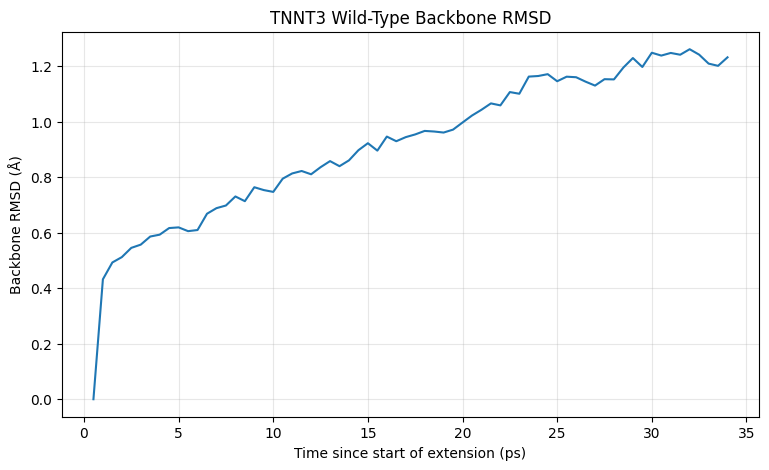

Number of frames: 68
Mean RMSD (Å): 0.9202522
Final RMSD (Å): 1.2313901


In [ ]:
# Calculate backbone RMSD over the trajectory
import mdtraj as md
import numpy as np
import matplotlib.pyplot as plt

traj = md.load(
    "TNNT3_WT_equilibration.dcd",
    top="TNNT3_WT_small_minimized.pdb"
)

# Select protein backbone atoms
backbone = traj.topology.select("protein and backbone")

# Align frames to the first saved frame
traj.superpose(traj, 0, atom_indices=backbone)

rmsd = md.rmsd(
    traj,
    traj,
    0,
    atom_indices=backbone
)

# Frames were saved every 0.5 ps
time_ps = np.arange(1, traj.n_frames + 1) * 0.5

plt.figure(figsize=(9, 5))
plt.plot(time_ps, rmsd * 10)
plt.xlabel("Time since start of extension (ps)")
plt.ylabel("Backbone RMSD (Å)")
plt.title("TNNT3 Wild-Type Backbone RMSD")
plt.grid(alpha=0.3)
plt.show()

print("Number of frames:", traj.n_frames)
print("Mean RMSD (Å):", np.mean(rmsd) * 10)
print("Final RMSD (Å):", rmsd[-1] * 10)

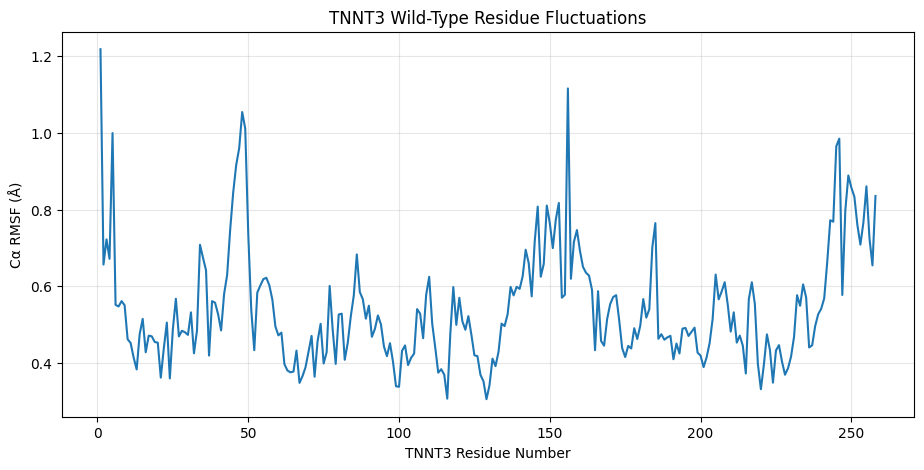

Mean RMSF: 0.5426903 Å
Maximum RMSF: 1.2181133 Å
Residue with maximum RMSF: 1


In [ ]:
# Calculate Cα RMSF
# Reload trajectory to avoid relying on previous modifications
traj = md.load(
    "TNNT3_WT_equilibration.dcd",
    top="TNNT3_WT_small_minimized.pdb"
)

# Select protein C-alpha atoms
ca_indices = traj.topology.select("protein and name CA")

# Align frames using protein backbone atoms
backbone_indices = traj.topology.select(
    "protein and backbone"
)

traj.superpose(
    traj,
    0,
    atom_indices=backbone_indices
)

# Calculate C-alpha RMSF in nanometers
rmsf = md.rmsf(
    traj,
    traj,
    0,
    atom_indices=ca_indices
)

# Convert to Angstroms
rmsf_angstrom = rmsf * 10

# Extract actual residue sequence numbers
residue_numbers = [
    traj.topology.atom(i).residue.resSeq
    for i in ca_indices
]

plt.figure(figsize=(11, 5))

plt.plot(
    residue_numbers,
    rmsf_angstrom,
    linewidth=1.5
)

plt.xlabel("TNNT3 Residue Number")
plt.ylabel("Cα RMSF (Å)")
plt.title("TNNT3 Wild-Type Residue Fluctuations")

plt.grid(alpha=0.3)
plt.show()

print("Mean RMSF:", np.mean(rmsf_angstrom), "Å")
print("Maximum RMSF:", np.max(rmsf_angstrom), "Å")
print(
    "Residue with maximum RMSF:",
    residue_numbers[np.argmax(rmsf_angstrom)]
)

In [ ]:
# Examine residue 63
# Extract residues 58–68
mask = (
    (np.array(residue_numbers) >= 58) &
    (np.array(residue_numbers) <= 68)
)

print("RMSF around residue 63:")

for residue, fluctuation in zip(
    np.array(residue_numbers)[mask],
    rmsf_angstrom[mask]
):
    print(
        f"Residue {residue}: "
        f"{fluctuation:.3f} Å"
    )

RMSF around residue 63:
Residue 58: 0.565 Å
Residue 59: 0.495 Å
Residue 60: 0.472 Å
Residue 61: 0.479 Å
Residue 62: 0.397 Å
Residue 63: 0.380 Å
Residue 64: 0.376 Å
Residue 65: 0.378 Å
Residue 66: 0.432 Å
Residue 67: 0.348 Å
Residue 68: 0.366 Å
